# LaserCut GmbH — Exploratory Data Analysis (EDA)

**Scope:** Only the assignment step: explore the already-extended dataset using suitable statistics and visualizations, investigate relationships and unusual observations.

This notebook does **not** extract features from DXF files. It assumes your CSV already contains the geometric features.

## Questions
1. What do the feature distributions look like?
2. Are there missing or suspicious values?
3. Which features vary the most?
4. Which features appear related?
5. Which unusual parts should be inspected in their DXF drawings?

Expected feature columns: `width`, `height`, `cutting_length`, `number_of_holes`, `bounding_box_area`.

## 1. Load the dataset

Place this notebook in your project folder, or change `DATASET_PATH` to your CSV location.

In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATASET_PATH = Path("laserCut_fake_test_data.csv")  # Change if needed
df = pd.read_csv(DATASET_PATH)

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: 200 rows × 5 columns
Columns: ['bounding_box_width', 'bounding_box_height', 'cutting_length', 'number_of_holes', 'bounding_box_area']


,bounding_box_width,bounding_box_height,cutting_length,number_of_holes,bounding_box_area
0,141.89,102.34,563.46,0,14521.76
1,67.73,184.34,887.80,0,12484.79
2,181.32,89.34,566.72,0,16199.13
3,201.30,121.12,480.70,2,24382.48
4,41.03,27.52,131.95,0,1129.44


## 2. Select the features


In [ ]:
FEATURES = [
    "bounding_box_width",
    "bounding_box_height",
    "cutting_length",
    "number_of_holes",
    "bounding_box_area",
]
ID_COLUMNS = ["filename", "customer"]  # Edit to match your CSV

available_features = [c for c in FEATURES if c in df.columns]
missing_features = [c for c in FEATURES if c not in df.columns]
print("Available features:", available_features)

if not available_features:
    raise ValueError("No expected feature columns found. Edit FEATURES to match your CSV.")

for col in available_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

numeric_df = df[available_features].copy()

Available features: ['bounding_box_width', 'bounding_box_height', 'cutting_length', 'number_of_holes', 'bounding_box_area']
Missing expected features: []


## 3. Data quality and plausibility checks

Check data types, missing values, duplicates and negative measurements. Negative geometric measurements are usually suspicious and should be investigated.

In [13]:
print("Data types:")
display(df[available_features].dtypes.to_frame("dtype"))

print("\nMissing values:")
display(pd.DataFrame({
    "missing_count": numeric_df.isna().sum(),
    "missing_percent": (numeric_df.isna().mean() * 100).round(2)
}))

print(f"\nDuplicate complete rows: {df.duplicated().sum()}")

print("\nNegative values (review these):")
display((numeric_df < 0).sum().to_frame("negative_count"))

if {"width", "height", "bounding_box_area"}.issubset(df.columns):
    expected_area = df["width"] * df["height"]
    difference = (df["bounding_box_area"] - expected_area).abs()
    print("\nBounding-box area mismatches (> 1e-6):", (difference > 1e-6).sum())

Data types:


,dtype
bounding_box_width,float64
bounding_box_height,float64
cutting_length,float64
number_of_holes,int64
bounding_box_area,float64



Missing values:


,missing_count,missing_percent
bounding_box_width,0,0.0
bounding_box_height,0,0.0
cutting_length,0,0.0
number_of_holes,0,0.0
bounding_box_area,0,0.0



Duplicate complete rows: 0

Negative values (review these):


,negative_count
bounding_box_width,0
bounding_box_height,0
cutting_length,0
number_of_holes,0
bounding_box_area,0


## 4. Descriptive statistics

`describe()` gives count, mean, standard deviation, minimum, quartiles and maximum.

- **Mean vs. median:** a large difference can indicate skewness or extreme values.
- **Standard deviation:** spread, expressed in the feature's own units.
- **Quartiles:** describe the middle 50% of observations.
- **Minimum and maximum:** help identify unusual values.

In [14]:
summary = numeric_df.describe().T
summary["median"] = numeric_df.median()
summary["skewness"] = numeric_df.skew()
summary["missing"] = numeric_df.isna().sum()
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,median,skewness,missing
bounding_box_width,200.0,139.070,82.073,37.15,84.235,119.280,169.412,595.93,119.280,2.109,0
bounding_box_height,200.0,104.254,64.525,20.72,58.562,89.770,128.625,420.08,89.770,1.743,0
cutting_length,200.0,560.988,352.159,116.28,328.338,474.205,685.202,2769.10,474.205,2.428,0
number_of_holes,200.0,1.165,3.012,0.00,0.000,0.000,1.000,22.00,0.000,5.395,0
bounding_box_area,200.0,14810.281,14659.893,1129.44,6002.395,10039.145,17133.268,90851.35,10039.145,2.752,0


## 5. Feature distributions: histograms

Histograms show how frequently values occur across ranges.

Look for right/left skew, multiple peaks, long tails and extreme values. The plots use original units.

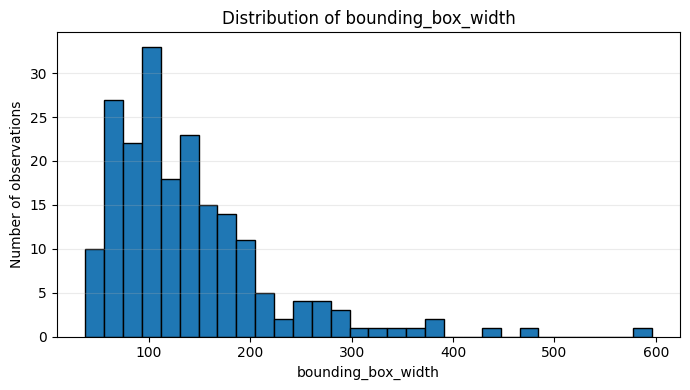

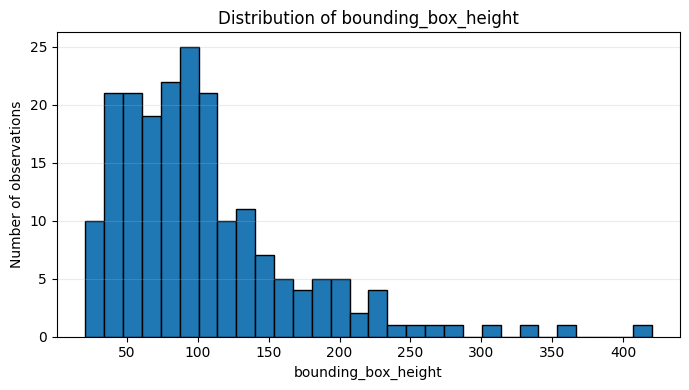

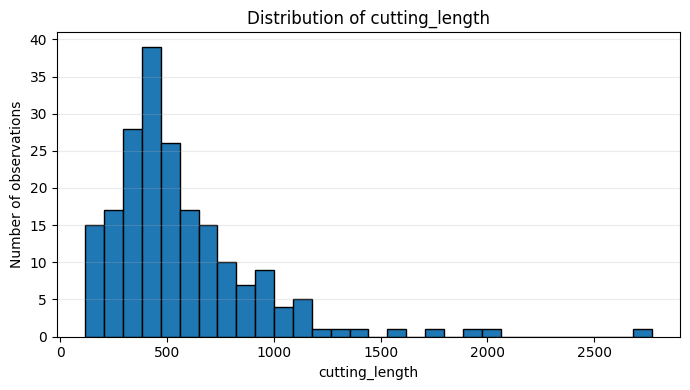

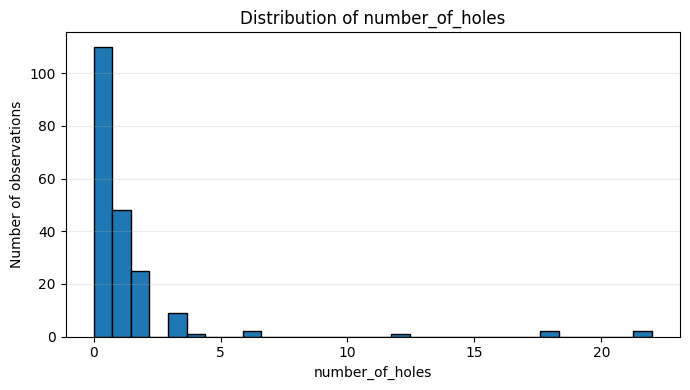

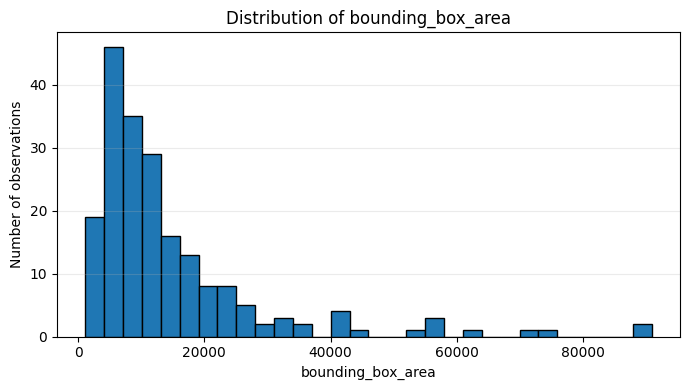

In [15]:
for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(values, bins=30, edgecolor="black")
    ax.set(title=f"Distribution of {feature}", xlabel=feature, ylabel="Number of observations")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 6. Boxplots and unusual observations

A boxplot summarizes the median and quartiles and highlights potential outliers.

The IQR rule flags values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

**An outlier is not automatically an error.** A very large or intricate part may be a genuine product.The DXF should be checked before deciding.

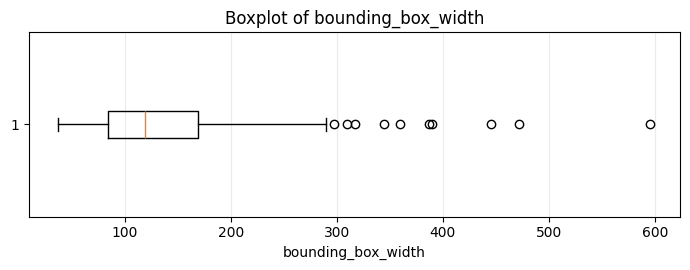

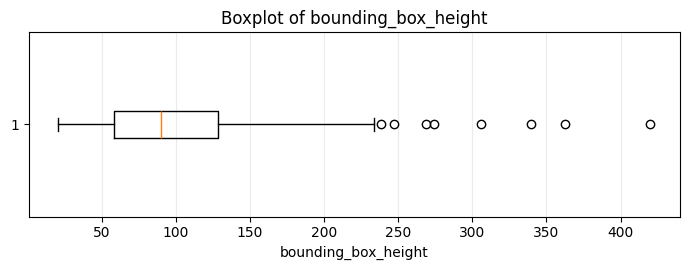

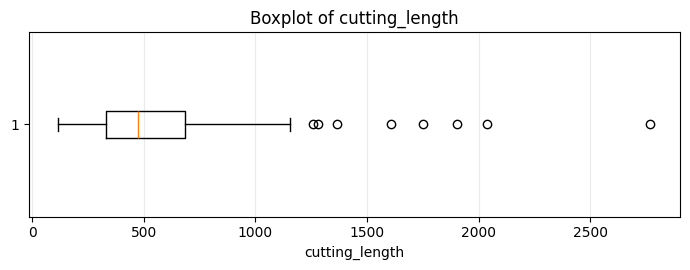

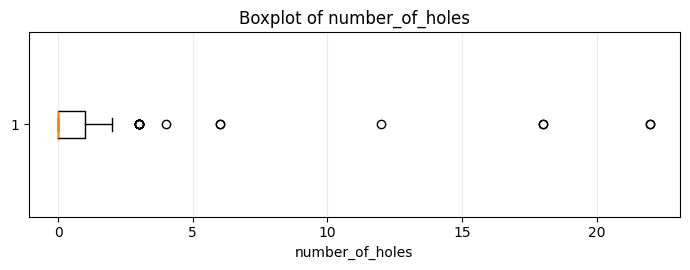

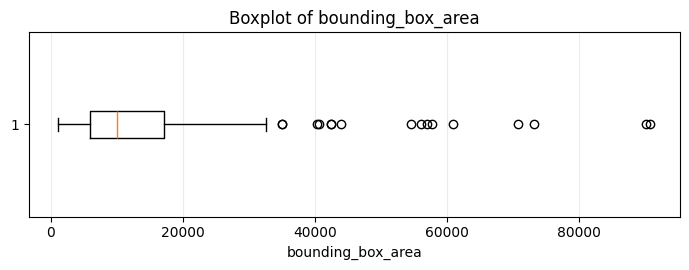

In [16]:
for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.boxplot(values, vert=False)
    ax.set(title=f"Boxplot of {feature}", xlabel=feature)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

In [17]:
outlier_rows = []

for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = numeric_df[feature].notna() & (
        (numeric_df[feature] < lower) | (numeric_df[feature] > upper)
    )
    for idx in df.index[mask]:
        row = {
            "row_index": idx, "feature": feature, "value": df.loc[idx, feature],
            "lower_bound": lower, "upper_bound": upper
        }
        for id_col in ID_COLUMNS:
            if id_col in df.columns:
                row[id_col] = df.loc[idx, id_col]
        outlier_rows.append(row)

outliers = pd.DataFrame(outlier_rows)
if outliers.empty:
    print("No IQR outliers detected.")
else:
    display(outliers.sort_values(["feature", "value"], ascending=[True, False]))

,row_index,feature,value,lower_bound,upper_bound
55,153,bounding_box_area,90851.35,-10693.91375,33829.57625
50,88,bounding_box_area,90119.78,-10693.91375,33829.57625
48,48,bounding_box_area,73227.95,-10693.91375,33829.57625
54,139,bounding_box_area,70798.01,-10693.91375,33829.57625
45,28,bounding_box_area,60984.67,-10693.91375,33829.57625
53,138,bounding_box_area,57743.53,-10693.91375,33829.57625
56,162,bounding_box_area,56994.19,-10693.91375,33829.57625
57,168,bounding_box_area,56095.67,-10693.91375,33829.57625
43,26,bounding_box_area,54585.51,-10693.91375,33829.57625
52,124,bounding_box_area,43950.07,-10693.91375,33829.57625


## 7. Relationships: correlation matrix

Pearson correlation measures the strength and direction of **linear** relationships.

- Near `+1`: strong positive linear association.
- Near `-1`: strong negative linear association.
- Near `0`: weak linear association.

Correlation does not prove causation and can miss nonlinear relationships. Extreme observations can influence it.

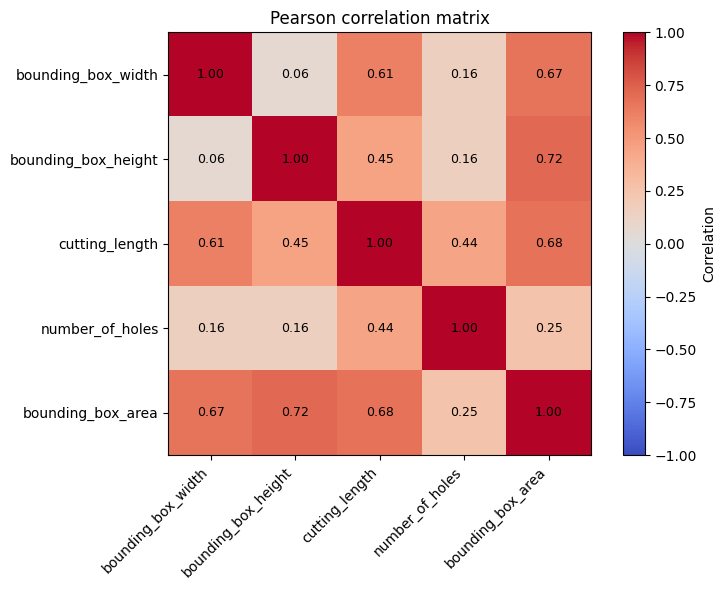

,bounding_box_width,bounding_box_height,cutting_length,number_of_holes,bounding_box_area
bounding_box_width,1.000,0.059,0.610,0.156,0.669
bounding_box_height,0.059,1.000,0.445,0.156,0.716
cutting_length,0.610,0.445,1.000,0.444,0.677
number_of_holes,0.156,0.156,0.444,1.000,0.252
bounding_box_area,0.669,0.716,0.677,0.252,1.000


In [18]:
correlation = numeric_df.corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.index)))
ax.set_xticklabels(correlation.columns, rotation=45, ha="right")
ax.set_yticklabels(correlation.index)
ax.set_title("Pearson correlation matrix")

for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        value = correlation.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()
display(correlation.round(3))

## 8. Scatterplots: investigate engineering questions

Recommended comparisons:

1. **Bounding box area vs. cutting length:** do larger envelopes tend to have longer cutting paths?
2. **Number of holes vs. cutting length:** do parts with more holes tend to have longer cutting paths?
3. **Width vs. height:** are parts concentrated around particular proportions?
4. **Bounding box area vs. number of holes:** are larger parts also more perforated?

Look for trends, clusters, curved patterns and isolated points. A trend is an association, not proof of causation.

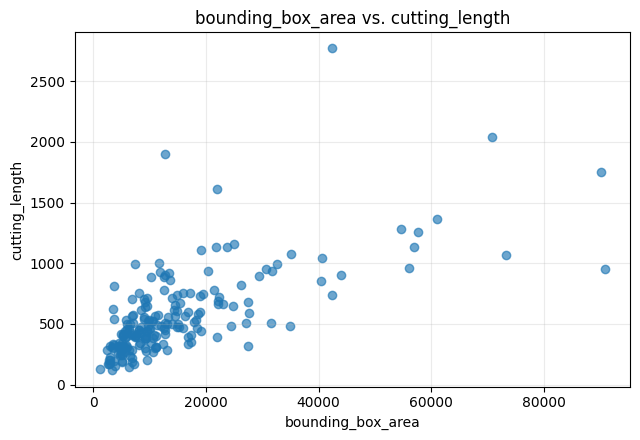

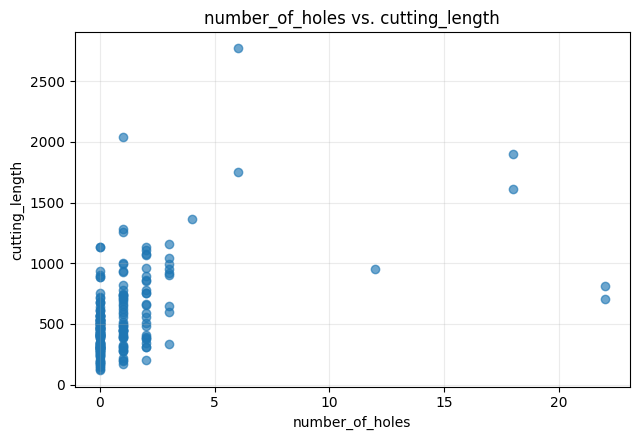

Skipping width vs. height: column missing.


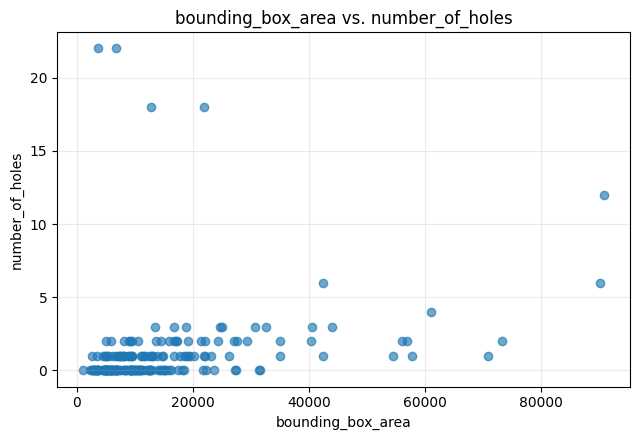

In [19]:
recommended_pairs = [
    ("bounding_box_area", "cutting_length"),
    ("number_of_holes", "cutting_length"),
    ("width", "height"),
    ("bounding_box_area", "number_of_holes"),
]

for x_col, y_col in recommended_pairs:
    if x_col not in df.columns or y_col not in df.columns:
        print(f"Skipping {x_col} vs. {y_col}: column missing.")
        continue
    plot_data = df[[x_col, y_col]].dropna()
    if plot_data.empty:
        print(f"Skipping {x_col} vs. {y_col}: no complete observations.")
        continue
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.scatter(plot_data[x_col], plot_data[y_col], alpha=0.65)
    ax.set(title=f"{x_col} vs. {y_col}", xlabel=x_col, ylabel=y_col)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## 9. Retrieve the unusual rows for DXF inspection

For each unusual row:

1. Find its filename or part identifier.
2. Open the corresponding DXF.
3. Check whether the unusual value reflects a genuine design (large envelope, long contour, many internal features).
4. Check for extraction/data issues (wrong units, duplicate geometry, unsupported DXF entities).

In [20]:
if not outliers.empty:
    unusual_indices = sorted(outliers["row_index"].unique())
    columns_to_show = [c for c in ID_COLUMNS + available_features if c in df.columns]
    display(df.loc[unusual_indices, columns_to_show])
else:
    print("There are no IQR-flagged rows to display.")

,bounding_box_width,bounding_box_height,cutting_length,number_of_holes,bounding_box_area
6,128.74,53.46,707.03,22,6882.10
26,160.82,339.43,1278.66,1,54585.51
27,146.71,238.63,482.12,1,35010.45
28,445.98,136.74,1367.06,4,60984.67
30,389.71,38.01,737.55,1,14811.45
38,76.25,47.39,813.98,22,3613.20
39,344.37,117.98,1040.47,3,40630.09
44,127.95,274.17,1071.86,2,35080.69
48,174.32,420.08,1064.12,2,73227.95
73,157.74,268.78,741.24,1,42396.62


## 10. Findings and interpretation — complete after running the notebook

Use your actual outputs to answer:

### Distributions
- Which feature has the largest spread?
- Which features are skewed?
- Are there multiple clusters or peaks?

### Relationships
- Which pairs have the strongest correlations?
- Does bounding box area appear related to cutting length?
- Does hole count appear related to cutting length?
- Do scatterplots reveal clusters or nonlinear patterns?

### Unusual observations
- Which parts are flagged by the IQR rule?
- Are they genuine designs or possible data/extraction errors?
- What do their DXF drawings show?

### Manufacturing interpretation
- Cutting length can approximate laser travel distance, but is not a direct measure of cutting time.
- Hole count may indicate internal contours and piercing operations, depending on how holes are defined and detected.
- Bounding box dimensions describe the overall envelope, not actual material area or retrieval difficulty.
- Small or intricate parts may be difficult to retrieve even if their cutting length is not especially high.

### Limitations
Mention factors not represented by these geometric features, such as material, thickness, cutting speed, machine settings, piercing time, sheet layout/nesting and physical handling.

**Do not write conclusions before inspecting your actual outputs.** The notebook provides evidence; your interpretation should describe what that evidence supports.